# BigML: Coding 

Alexander Lio

Env and Imports

In [35]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader

from spuco.datasets import SpuCoMNIST, SpuriousFeatureDifficulty
from spuco.evaluate import Evaluator
from spuco.group_inference import GeorgeInference
from spuco.models import model_factory
from spuco.robust_train import ERM, GroupBalanceBatchERM
from spuco.utils import set_seed

Reproducibility and Setup

In [36]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = None

if torch.backends.mps.is_available():
  DEVICE = torch.device('mps')
elif torch.cuda.is_available():
  DEVICE = torch.device('cuda')
else:
  DEVICE = torch.device('cpu')

print("Seed:", SEED)
print("Device:", DEVICE)

Seed: 42
Device: mps


Load SpuCoMNIST

Only the required arguments (classes, difficulty) and the train-split correlation strength are set, following the SpuCo quickstart. All other parameters are left at their defaults. `cm.get_cmap` patched because I am on a newer matplotlib version, did not want to reset venv.

In [ ]:
import matplotlib
import matplotlib.cm as cm

set_seed(SEED)

if not hasattr(cm, "get_cmap"):
    cm.get_cmap = lambda name, lut=None: matplotlib.colormaps[name]

ROOT = "./data/mnist/"
CLASSES = [[0, 1], [2, 3], [4, 5], [6, 7], [8, 9]]
DIFFICULTY = SpuriousFeatureDifficulty.MAGNITUDE_LARGE

trainset = SpuCoMNIST(
    root=ROOT,
    spurious_feature_difficulty=DIFFICULTY,
    spurious_correlation_strength=0.9,
    classes=CLASSES,
    split="train",
)
trainset.initialize()

valset = SpuCoMNIST(
    root=ROOT,
    spurious_feature_difficulty=DIFFICULTY,
    classes=CLASSES,
    split="val",
)
valset.initialize()

testset = SpuCoMNIST(
    root=ROOT,
    spurious_feature_difficulty=DIFFICULTY,
    classes=CLASSES,
    split="test",
)
testset.initialize()

In [38]:
print(len(trainset), len(valset), len(testset))
image, label = trainset[0]
print(image.shape, label)

for group, idx in sorted(trainset.group_partition.items()):
    print(group, len(idx))

48004 11996 10000
torch.Size([3, 28, 28]) 2
(0, 0) 10082
(0, 1) 11
(0, 2) 15
(0, 3) 10
(0, 4) 15
(1, 0) 13
(1, 1) 9623
(1, 2) 11
(1, 3) 8
(1, 4) 17
(2, 0) 13
(2, 1) 9
(2, 2) 8965
(2, 3) 14
(2, 4) 10
(3, 0) 14
(3, 1) 11
(3, 2) 11
(3, 3) 9698
(3, 4) 13
(4, 0) 12
(4, 1) 13
(4, 2) 13
(4, 3) 10
(4, 4) 9393


Visualize the data

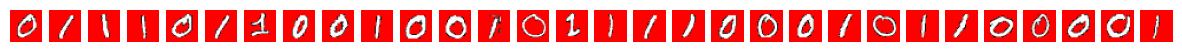

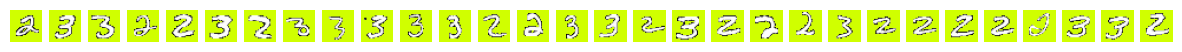

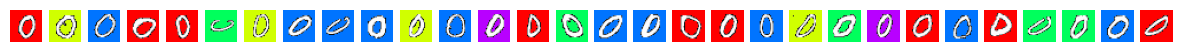

In [46]:
def visualize(dataset, class_index, num=30):
    idx = [i for i, y in enumerate(dataset.labels) if y == class_index][:num]
    fig, axes = plt.subplots(1, num, figsize=(num * 0.5, 1))
    for ax, i in zip(axes, idx):
        ax.imshow(dataset[i][0].permute(1, 2, 0))
        ax.axis("off")
    plt.show()

visualize(trainset, 0)
visualize(trainset, 1) 
visualize(valset, 0) 

Define ERM Model + Train

In [40]:
set_seed(SEED)
model = model_factory("lenet", trainset[0][0].shape, trainset.num_classes).to(DEVICE)

# lr lowered from the ERM quickstart's 1e-2 to GEORGE quickstart
erm = ERM(
    model=model,
    trainset=trainset,
    batch_size=64,
    optimizer=torch.optim.SGD(model.parameters(), lr=1e-3, momentum=0.9, nesterov=True),
    num_epochs=2,
    max_grad_norm=1.0,
    device=DEVICE,
    verbose=False,
)
erm.train()

/Users/alexanderlio/Desktop/BigML-SpuCo/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Evaluate the ERM Baseline

In [ ]:
evaluator = Evaluator(
    testset=testset, 
    group_partition=testset.group_partition,
    group_weights=trainset.group_weights, 
    batch_size=512,
    model=model, 
    device=DEVICE, 
    verbose=True
)
evaluator.evaluate()

erm_results = (evaluator.worst_group_accuracy[1], evaluator.average_accuracy)
print(evaluator.worst_group_accuracy, evaluator.average_accuracy)

Evaluating group-wise accuracy:   4%|▍         | 1/25 [00:08<03:34,  8.93s/it]

Group (0, 0) Accuracy: 100.0


Evaluating group-wise accuracy:   8%|▊         | 2/25 [00:17<03:15,  8.49s/it]

Group (0, 1) Accuracy: 0.0


Evaluating group-wise accuracy:  12%|█▏        | 3/25 [00:25<03:03,  8.33s/it]

...

Group (4, 2) Accuracy: 0.0


Evaluating group-wise accuracy:  96%|█████████▌| 24/25 [03:10<00:07,  7.75s/it]

Group (4, 3) Accuracy: 0.0


Evaluating group-wise accuracy: 100%|██████████| 25/25 [03:18<00:00,  7.93s/it]

Group (4, 4) Accuracy: 100.0
((0, 1), 0.0) 99.49379218398467


Extract ERM Features

In [42]:
@torch.no_grad()
def extract(model, dataset, batch_size=512):
    model.eval()
    feats = []
    for x, _ in DataLoader(dataset, batch_size=batch_size, shuffle=False):
        x = x.to(DEVICE)
        f = model.backbone(x) if hasattr(model, "backbone") else model(x)
        feats.append(f.flatten(1).cpu())
    return torch.cat(feats)

features = extract(model, trainset)
labels = np.array(trainset.labels)
print(features.shape, labels.shape)

torch.Size([48004, 84]) (48004,)


Cluster Examples (GEORGE group inference)

In [43]:
george_infer = GeorgeInference(
    Z=features,
    class_labels=trainset.labels,
    device=torch.device("cpu"),
    max_clusters=5,
    verbose=True,
)
group_partition = george_infer.infer_groups()

print(len(group_partition), "groups")
print({k: len(v) for k, v in group_partition.items()})

Clustering class-wise: 100%|██████████| 5/5 [00:15<00:00,  3.06s/it]

18 groups
{(2, 0): 8965, (2, 1): 46, (0, 0): 3577, (0, 1): 914, (0, 2): 558, (0, 3): 51, (0, 4): 3961, (0, 5): 1072, (4, 0): 9393, (4, 1): 48, (1, 0): 4245, (1, 1): 818, (1, 2): 3557, (1, 3): 1052, (3, 0): 3168, (3, 1): 196, (3, 2): 5636, (3, 3): 747}


Discovered Groups

In [44]:
true_s = np.array(trainset.spurious)

rows = []
for key, idx in group_partition.items():
    counts = pd.Series(true_s[idx]).value_counts()
    rows.append({"pseudo-group": str(key), "size": len(idx),
                 **{f"color {c}": int(counts.get(c, 0)) for c in range(5)}})
pd.DataFrame(rows).sort_values("pseudo-group").reset_index(drop=True)

,pseudo-group,size,color 0,color 1,color 2,color 3,color 4
0,"(0, 0)",3577,3577,0,0,0,0
1,"(0, 1)",914,914,0,0,0,0
2,"(0, 2)",558,558,0,0,0,0
3,"(0, 3)",51,0,11,15,10,15
4,"(0, 4)",3961,3961,0,0,0,0
5,"(0, 5)",1072,1072,0,0,0,0
6,"(1, 0)",4245,0,4245,0,0,0
7,"(1, 1)",818,0,818,0,0,0
8,"(1, 2)",3557,13,3508,11,8,17
9,"(1, 3)",1052,0,1052,0,0,0


Group-Balanced Retraining 

In [45]:
set_seed(SEED)
group_balanced_model = model_factory("lenet", trainset[0][0].shape, trainset.num_classes).to(DEVICE)

group_balance = GroupBalanceBatchERM(
    model=group_balanced_model,
    group_partition=group_partition,
    num_epochs=10,
    trainset=trainset,
    batch_size=64,
    optimizer=torch.optim.SGD(group_balanced_model.parameters(), lr=1e-3, momentum=0.9),
    device=DEVICE,
    verbose=False,
)
group_balance.train()

/Users/alexanderlio/Desktop/BigML-SpuCo/.venv/lib/python3.14/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Evaluate the Retrained Model

In [47]:
evaluator_gb = Evaluator(
    testset=testset, 
    group_partition=testset.group_partition,
    group_weights=trainset.group_weights, 
    batch_size=512,
    model=group_balanced_model, 
    device=DEVICE, 
    verbose=True
)
evaluator_gb.evaluate()

group_balanced_results = (evaluator_gb.worst_group_accuracy[1], evaluator_gb.average_accuracy)
print(evaluator_gb.worst_group_accuracy, evaluator_gb.average_accuracy)

Evaluating group-wise accuracy:   4%|▍         | 1/25 [00:07<03:03,  7.65s/it]

Group (0, 0) Accuracy: 99.76359338061465


Evaluating group-wise accuracy:   8%|▊         | 2/25 [00:15<02:55,  7.65s/it]

Group (0, 1) Accuracy: 82.03309692671395


Evaluating group-wise accuracy:  12%|█▏        | 3/25 [00:22<02:47,  7.64s/it]

...

Group (4, 2) Accuracy: 59.949622166246854


Evaluating group-wise accuracy:  96%|█████████▌| 24/25 [03:04<00:07,  7.65s/it]

Group (4, 3) Accuracy: 60.101010101010104


Evaluating group-wise accuracy: 100%|██████████| 25/25 [03:12<00:00,  7.72s/it]

Group (4, 4) Accuracy: 99.74747474747475
((1, 3), 0.0) 98.68276352238568


Compare ERM vs. GEORGE Retraining

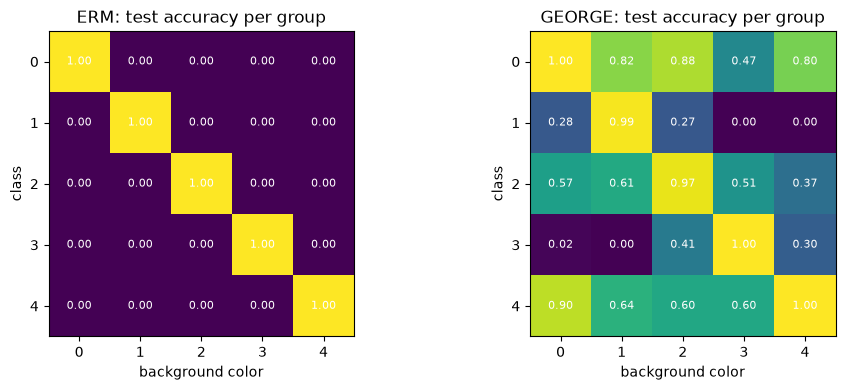

{'ERM': (np.float64(0.2), np.float64(0.0)), 'GEORGE': (np.float64(0.559), np.float64(0.452))}


In [49]:
comparison = pd.DataFrame(
    [["ERM", erm_results[1], erm_results[0]],
     ["GEORGE (group-balanced)", group_balanced_results[1], group_balanced_results[0]]],
    columns=["Method", "Average Accuracy", "Worst-Group Accuracy"],
)
comparison

@torch.no_grad()
def group_acc(model, dataset, batch_size=512):
    model.eval()
    preds = torch.cat([model(x.to(DEVICE)).argmax(1).cpu()
                       for x, _ in DataLoader(dataset, batch_size=batch_size)]).numpy()
    y = np.array(dataset.labels)
    return np.array([[(preds[dataset.group_partition[(c, s)]] == y[dataset.group_partition[(c, s)]]).mean()
                      for s in range(5)] for c in range(5)])

grids = {"ERM": group_acc(model, testset), "GEORGE": group_acc(group_balanced_model, testset)}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, g) in zip(axes, grids.items()):
    ax.imshow(g, vmin=0, vmax=1, cmap="viridis")
    ax.set_title(f"{name}: test accuracy per group")
    ax.set_xlabel("background color"); ax.set_ylabel("class")
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{g[i, j]:.2f}", ha="center", va="center", color="white", fontsize=8)
plt.tight_layout(); plt.show()
print({n: (g.mean().round(3), g[~np.eye(5, dtype=bool)].mean().round(3)) for n, g in grids.items()})  # (all-group mean, off-diagonal mean)